# **Classification: Customer Churn Prediction**

This notebook recreates the customer-churn case study with the current `utils` API. It covers business understanding, EDA, leakage-safe splitting, preprocessing, feature selection, baseline models, cross-validated comparison, tuning, final test evaluation, and business impact.

**Target:** `churn` (1 = churned, 0 = retained).

**Primary metric:** Recall for the churn class, because a missed at-risk customer is usually more expensive than a false alarm. Precision and F1 are reported to keep retention costs under control.

## **STAGE 0: BUSINESS UNDERSTANDING**

### Problem statement
A telecommunications company is losing customers to competitors. Retention efforts are currently reactive: the team contacts customers after they have already left. Acquisition costs are much higher than retention costs, so preventing churn is a major financial lever.

### Role
As the data science team, we will:
- Explore customer behavior and service usage.
- Identify the strongest churn indicators.
- Build a model that flags at-risk customers before they leave.
- Translate model performance into a retention-cost and revenue-saved estimate.

### Goals
- **Primary:** identify at-risk customers early enough for intervention.
- **Secondary:** prioritize high-value customers and allocate retention budget efficiently.
- **Tertiary:** explain the top churn drivers to business stakeholders.

### Business metrics
| Metric | Description | Role |
|---|---|---|
| Churn rate (%) | Share of customers who leave in a period | Main |
| Retention rate (%) | Share of targeted customers retained | Main |
| Customer lifetime value | Revenue over the customer relationship | Secondary |
| Cost per acquisition | Cost to replace a lost customer | Secondary |

### Success criteria
- Recall for churn ≥ 0.80 on the validation/test data.
- Precision ≥ 0.60 so retention resources are not wasted.
- A clear, stable set of top churn indicators.
- A positive expected net benefit under explicit retention assumptions.

## **STAGE 1: PROJECT SETUP**

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from utils import (
    analyze_categorical_relationships,
    calculate_correlation_tabular,
    calculate_feature_importance,
    check_data_information,
    compare_cv_metrics_classification,
    describe_categorical_combined,
    describe_numerical_combined,
    eval_classification,
    feature_encoding,
    feature_scaling,
    filter_outliers,
    get_model_pipeline_classification,
    handle_missing_values,
    plot_correlation_heatmap,
    plot_dynamic_countplot,
    plot_dynamic_hisplots_kdeplots,
    tune_single_model_classification,
)

warnings.filterwarnings("ignore")
sns.set_style("darkgrid")
pd.set_option("display.max_columns", None)

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data" / "classification_data.csv"
print(f"Project root: {PROJECT_ROOT}")
print(f"Data path:    {DATA_PATH}")

Project root: e:\Data Science Utils
Data path:    e:\Data Science Utils\data\classification_data.csv


## **STAGE 2: LOAD AND INSPECT THE DATA**

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Rows: 1,050 | Columns: 18


,customer_id,age,gender,tenure_months,monthly_charges,total_charges,contract_type,payment_method,support_tickets,account_balance,internet_service,online_security,satisfaction_score,days_since_last_login,num_products,referral_source,churn,churn_label
0,CUST_00352,52.0,Female,13.0,64.393115,855.8778833905786,Two year,Bank Transfer,1,58.950305,Fiber optic,True,1.6,6.0,1,Friend,1,Yes
1,CUST_00689,46.0,Male,81.0,115.102595,9029.757263810074,Two year,Electronic Check,1,-25.965241,Fiber optic,Yes,4.5,4.0,4,Billboard,0,No
2,CUST_00485,18.0,Other,44.0,74.210796,3123.9632752803795,One year,Credit Card,4,133.015936,DSL,True,3.0,11.0,4,Email,0,No
3,CUST_00388,54.0,Male,9.0,20.353377,179.8634663715755,One year,Bank Transfer,4,-13.197764,No,Yes,2.6,11.0,1,Google,1,Yes
4,CUST_00031,67.0,Female,0.0,90.937098,0.0,One year,Electronic Check,4,-95.459565,DSL,yes,3.3,63.0,1,Facebook,1,Yes


In [3]:
info_df = check_data_information(df, df.columns.tolist())
display(info_df)

,Feature,Data Type,Null Values,Null Percentage,Zero Values,Zero Percentage,Negative Values,Negative Percentage,Empty Strings,Numeric in Object,Duplicated Values,Unique Values,Cardinality Ratio,Unique Sample
0,customer_id,object,0,0.00,0,0.00,0,0.00,0,0,50,1000,0.9524,"CUST_00352, CUST_00689, CUST_00485, CUST_00388..."
1,age,float64,80,7.62,0,0.00,9,0.86,0,0,50,80,0.0762,"52.0, 46.0, 18.0, 54.0, 67.0"
2,gender,object,0,0.00,0,0.00,0,0.00,0,0,50,5,0.0048,"Female, Male, Other, FEMALE, male"
3,tenure_months,float64,99,9.43,91,8.67,0,0.00,0,0,50,95,0.0905,"13.0, 81.0, 44.0, 9.0, 0.0"
4,monthly_charges,float64,91,8.67,0,0.00,37,3.52,0,0,50,913,0.8695,"64.39311525514046, 115.10259485286996, 74.2107..."
5,total_charges,object,105,10.00,0,0.00,0,0.00,35,891,50,780,0.7429,"855.8778833905786, 9029.757263810074, 3123.963..."
6,contract_type,object,7,0.67,0,0.00,0,0.00,0,0,50,4,0.0038,"Two year, One year, Month-to-month, monthly, nan"
7,payment_method,object,66,6.29,0,0.00,0,0.00,22,0,50,5,0.0048,"Bank Transfer, Electronic Check, Credit Card, ..."
8,support_tickets,int64,0,0.00,144,13.71,0,0.00,0,0,50,8,0.0076,"1, 4, 2, 0, 3"
9,account_balance,float64,0,0.00,0,0.00,527,50.19,0,0,50,1000,0.9524,"58.9503049877248, -25.965240829469444, 133.015..."


### Feature dictionary
| Feature | Description | Type |
|---|---|---|
| `customer_id` | Unique customer identifier | ID |
| `age` | Customer age | Numeric |
| `gender` | Customer gender | Categorical |
| `tenure_months` | Months as a customer | Numeric |
| `monthly_charges` | Monthly billing amount | Numeric |
| `total_charges` | Cumulative charges (stored as text with blanks) | Numeric |
| `contract_type` | Contract commitment | Ordinal |
| `payment_method` | Payment method | Nominal |
| `support_tickets` | Number of support requests | Numeric |
| `account_balance` | Current account balance (can be negative credit) | Numeric |
| `internet_service` | Internet service type | Nominal |
| `online_security` | Has online security add-on | Binary |
| `satisfaction_score` | Satisfaction score (1–5) | Numeric |
| `days_since_last_login` | Engagement recency | Numeric |
| `num_products` | Number of products subscribed | Numeric |
| `referral_source` | Acquisition source | Nominal |
| `churn` | Target: churned (1/0) | Binary |
| `churn_label` | Text version of the target | Binary |

## **STAGE 3: DATA CLEANING AND NORMALIZATION**

The raw file contains inconsistent category spellings, text values in a numeric column, negative billing values, impossible ages, and duplicate rows. These are data-quality fixes, not target-dependent modeling decisions.

In [4]:
# Normalize inconsistent category labels.
df["gender"] = df["gender"].replace({
    "FEMALE": "Female", "female": "Female",
    "male": "Male", "MALE": "Male",
})
df["gender"] = df["gender"].fillna("Unknown")

df["internet_service"] = df["internet_service"].replace({
    "fiber": "Fiber Optic", "Fiber optic": "Fiber Optic",
    "dsl": "DSL",
})

df["contract_type"] = df["contract_type"].replace({
    "Month-to-month": "Monthly", "monthly": "Monthly",
    "one_year": "One year", "two_year": "Two year",
})

df["online_security"] = df["online_security"].replace({
    "True": "Yes", "true": "Yes", "yes": "Yes", "1": "Yes",
    "NO": "No", "no": "No", "0": "No",
})

df["payment_method"] = (
    df["payment_method"]
    .replace({"": "Unknown", " ": "Unknown"})
    .fillna("Unknown")
)
df["referral_source"] = df["referral_source"].fillna("Unknown")

# total_charges is text because of blanks and "Pending" placeholders.
df["total_charges"] = df["total_charges"].replace(r"^\s*$", np.nan, regex=True)
df["total_charges"] = df["total_charges"].replace(
    ["Pending", "pending", "PENDING"], np.nan
)
df["total_charges"] = pd.to_numeric(df["total_charges"], errors="coerce")

print("Normalized categorical values:")
for col in ["gender", "contract_type", "payment_method", "internet_service", "online_security", "referral_source"]:
    print(f"  {col}: {sorted(df[col].dropna().astype(str).unique())}")

Normalized categorical values:
  gender: ['Female', 'Male', 'Other']
  contract_type: ['Monthly', 'One year', 'Two year']
  payment_method: ['Bank Transfer', 'Credit Card', 'Electronic Check', 'Mailed Check', 'Unknown']
  internet_service: ['DSL', 'Fiber Optic', 'No']
  online_security: ['No', 'Yes']
  referral_source: ['Billboard', 'Email', 'Facebook', 'Friend', 'Google', 'Instagram', 'Other', 'TV Ad', 'Twitter', 'Unknown']


In [5]:
# Treat physically impossible values as missing.
df.loc[(df["age"] < 18) | (df["age"] > 100), "age"] = np.nan
df.loc[df["monthly_charges"] < 0, "monthly_charges"] = np.nan
df.loc[df["total_charges"] < 0, "total_charges"] = np.nan

# Exact duplicate rows add no information.
df = df.drop_duplicates().reset_index(drop=True)

print(f"Shape after deduplication: {df.shape}")
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

Shape after deduplication: (1000, 18)


,missing_count
total_charges,160
monthly_charges,122
tenure_months,94
age,90
days_since_last_login,78
satisfaction_score,59
contract_type,7


## **STAGE 4: EXPLORATORY DATA ANALYSIS**

Target distribution:


,share
churn,
0,0.605
1,0.395


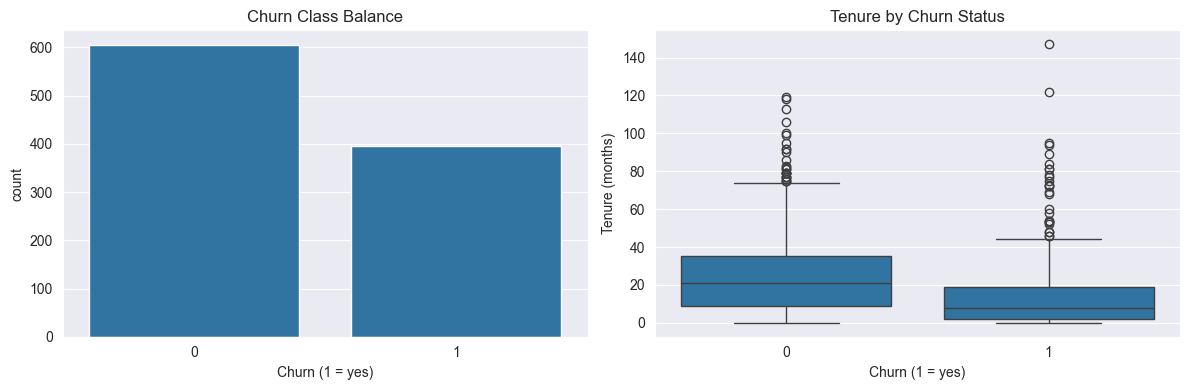

In [6]:
target = "churn"
target_label = "churn_label"

print("Target distribution:")
display(df[target].value_counts(normalize=True).rename("share").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x=target, ax=axes[0])
axes[0].set_title("Churn Class Balance")
axes[0].set_xlabel("Churn (1 = yes)")

sns.boxplot(data=df, x=target, y="tenure_months", ax=axes[1])
axes[1].set_title("Tenure by Churn Status")
axes[1].set_xlabel("Churn (1 = yes)")
axes[1].set_ylabel("Tenure (months)")

plt.tight_layout()
plt.show()

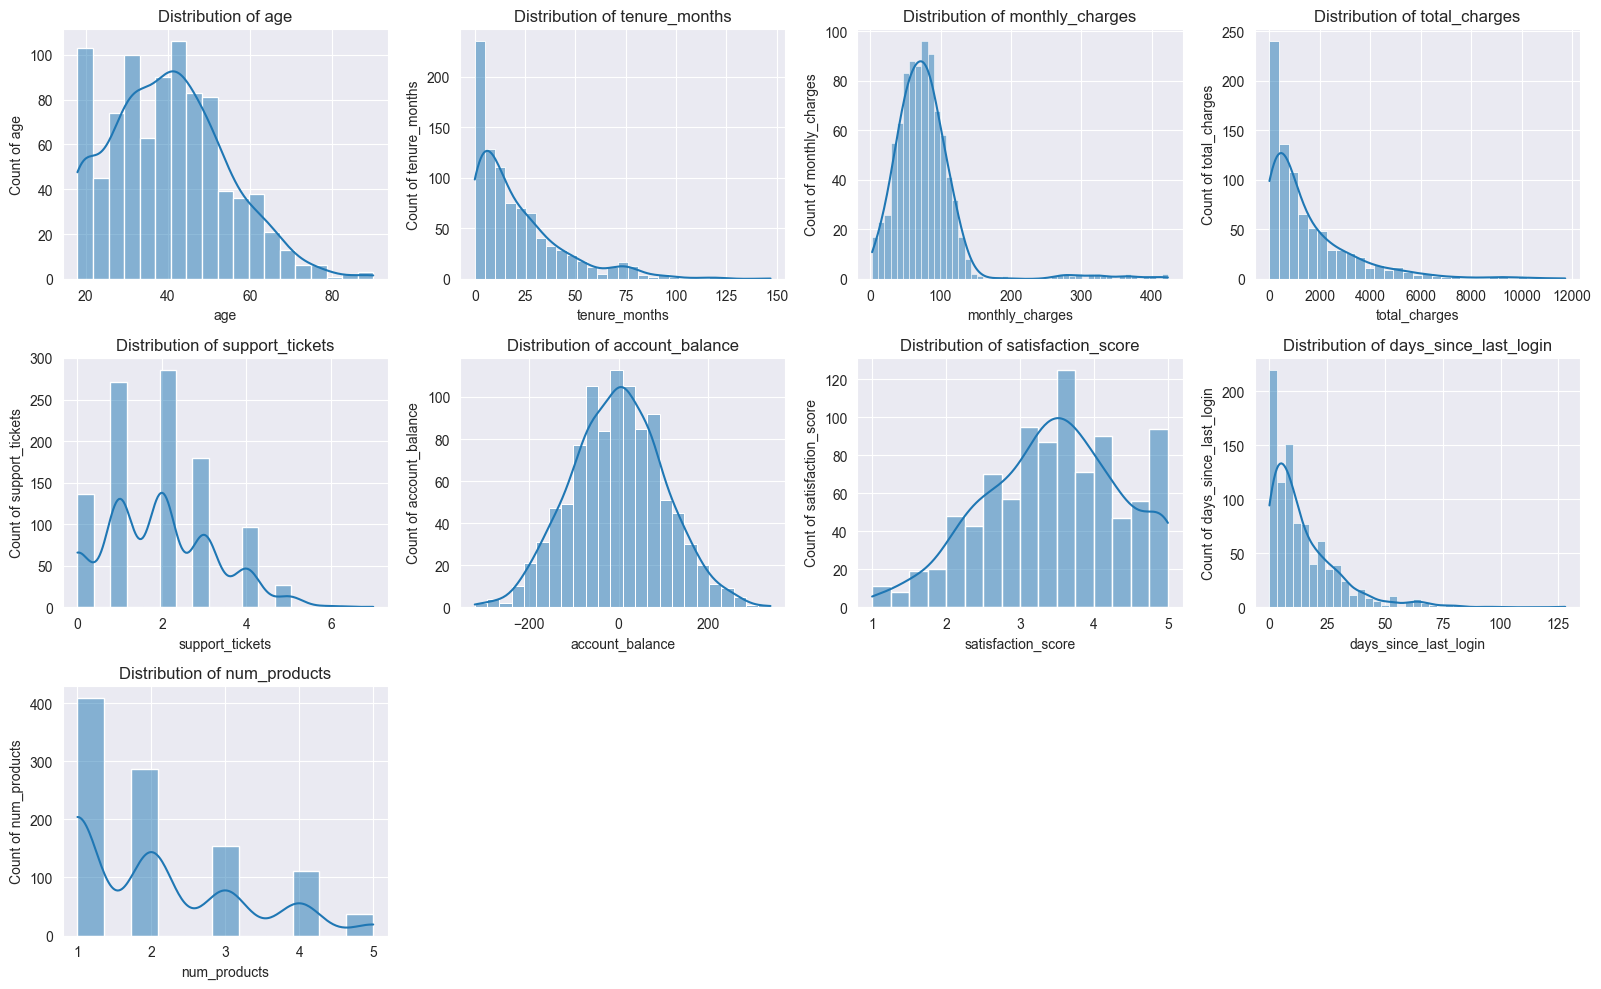

,Feature,overall_count,overall_mean,overall_std,overall_min,overall_25%,overall_50%,overall_75%,overall_max,overall_range,overall_IQR,overall_CV,overall_skewness,overall_kurtosis
0,age,910.0,40.160147,14.141940,18.000000,30.000000,40.000000,49.000000,90.009499,72.009499,19.000000,35.213865,0.439242,-0.039401
1,tenure_months,906.0,21.528698,22.457468,0.000000,5.000000,14.000000,30.000000,147.000000,147.000000,25.000000,104.314102,1.649114,3.110064
2,monthly_charges,878.0,77.892101,50.701608,2.853063,51.171136,72.535541,93.311875,422.784558,419.931495,42.140739,65.092105,3.332316,16.384414
3,total_charges,840.0,1538.392437,1819.993827,0.000000,318.322691,867.052526,2131.460772,11731.806760,11731.806760,1813.138081,118.304913,2.177711,5.928872
4,support_tickets,1000.0,1.927000,1.300524,0.000000,1.000000,2.000000,3.000000,7.000000,7.000000,2.000000,67.489563,0.457770,-0.204006
5,account_balance,1000.0,-2.138360,103.672112,-321.605720,-71.139539,-1.200905,68.211392,339.812732,661.418452,139.350931,-4848.205904,0.028404,-0.063702
6,satisfaction_score,941.0,3.448672,0.931923,1.000000,2.800000,3.500000,4.100000,5.000000,4.000000,1.300000,27.022652,-0.225861,-0.496219
7,days_since_last_login,922.0,14.613883,15.302542,0.000000,4.000000,10.000000,21.000000,128.000000,128.000000,17.000000,104.712364,2.072285,6.381762
8,num_products,1000.0,2.082000,1.159578,1.000000,1.000000,2.000000,3.000000,5.000000,4.000000,2.000000,55.695378,0.853646,-0.268968


In [7]:
nums_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cats_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
eda_nums = [col for col in nums_cols if col != target]

plot_dynamic_hisplots_kdeplots(df, eda_nums, ncols=4, figsize=(16, 10))
display(describe_numerical_combined(df, eda_nums))

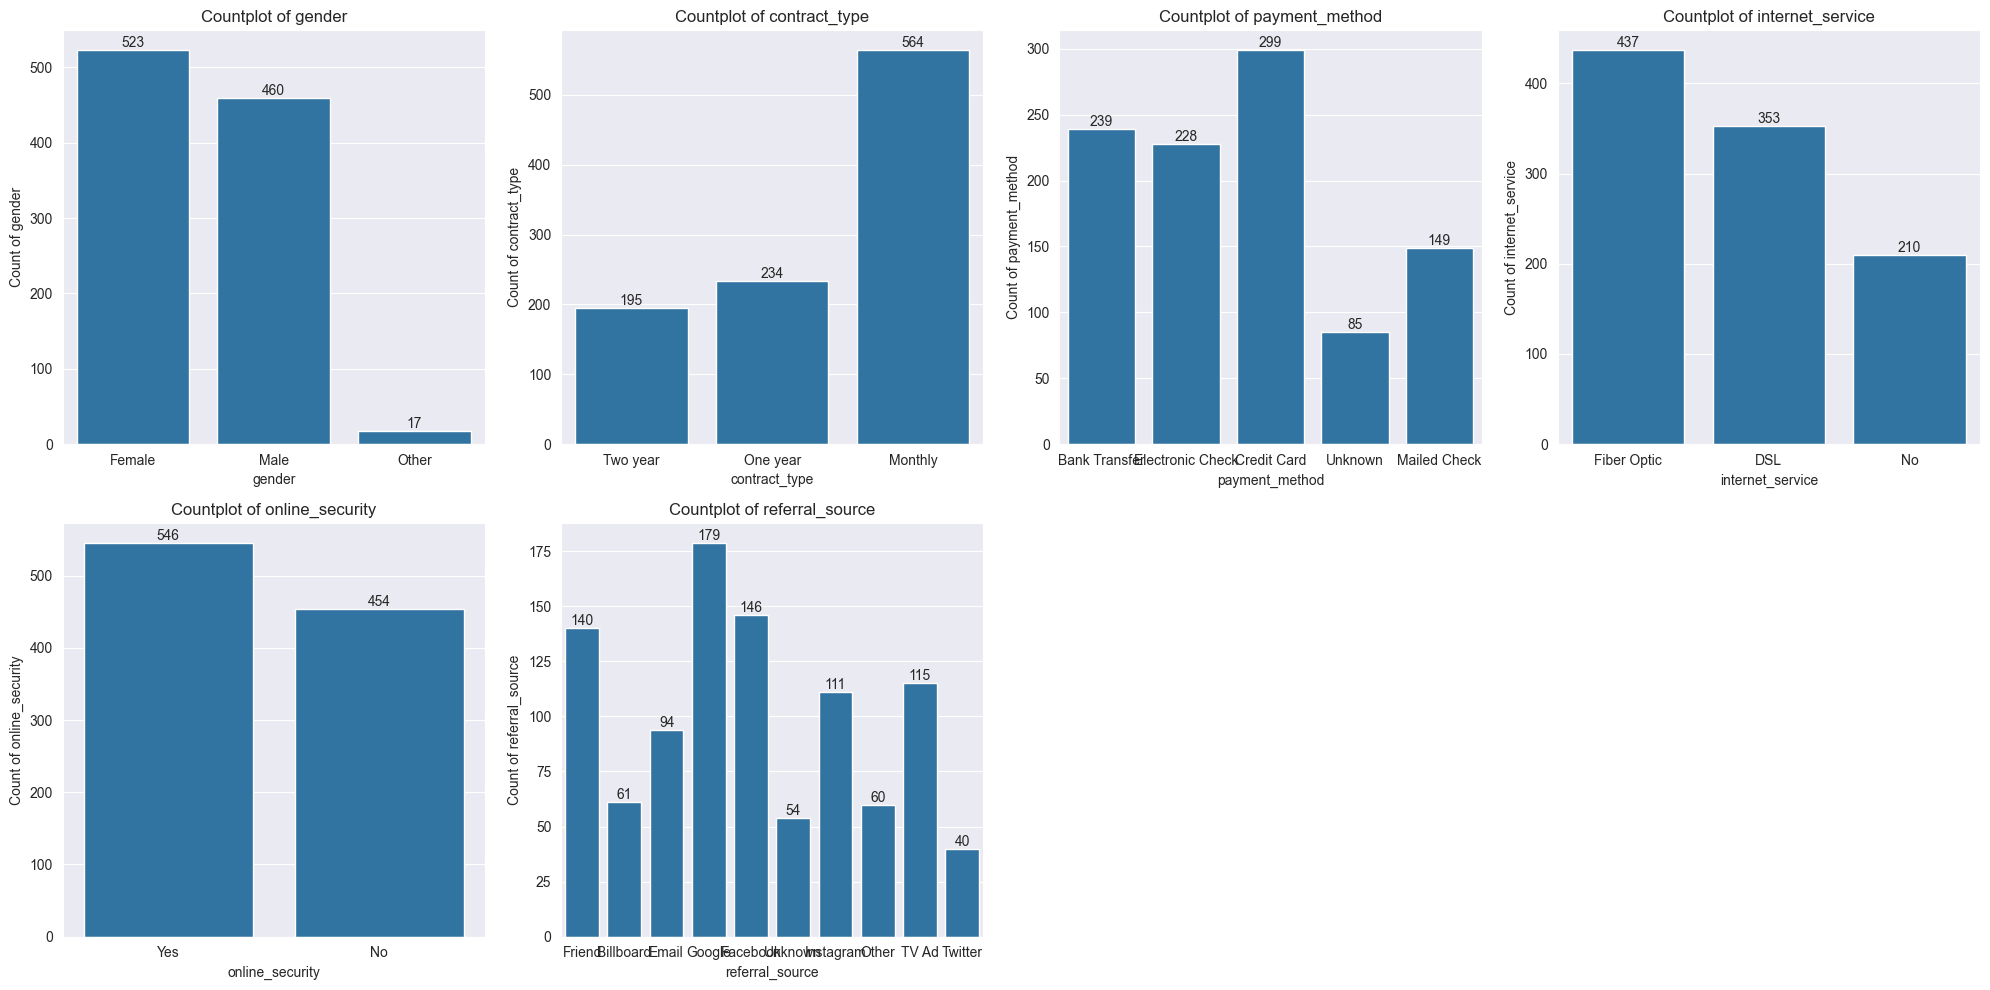

,Feature,overall_count,overall_unique,overall_top,overall_freq,overall_bottom,overall_freq_bottom,overall_top_percentage,overall_bottom_percentage,overall_n_categories
0,gender,1000,3,Female,523,Other,17,52.3,1.7,3
1,contract_type,993,3,Monthly,564,Two year,195,56.4,19.5,3
2,payment_method,1000,5,Credit Card,299,Unknown,85,29.9,8.5,5
3,internet_service,1000,3,Fiber Optic,437,No,210,43.7,21.0,3
4,online_security,1000,2,Yes,546,No,454,54.6,45.4,2
5,referral_source,1000,10,Google,179,Twitter,40,17.9,4.0,10


In [8]:
eda_cats = [col for col in cats_cols if col not in ["customer_id", "churn_label"]]

plot_dynamic_countplot(df, eda_cats, ncols=4, figsize=(20, 10))
display(describe_categorical_combined(df, eda_cats))


Chi-Square Analysis Results:
--------------------------------------------------------------------------------


,Feature,Chi-Square,P-Value,Cramér's V,Effect Size,Is Significant,Strongest Category,Association Direction
5,referral_source,10.384533,0.320261,0.101905,Small,False,Friend,Positive
2,payment_method,6.275061,0.179527,0.079215,Negligible,False,Unknown,Positive
0,gender,3.221662,0.199722,0.056760,Negligible,False,Other,Negative
3,internet_service,0.929969,0.628145,0.030495,Negligible,False,DSL,Positive
1,contract_type,0.697207,0.705673,0.026498,Negligible,False,One year,Positive
4,online_security,0.023108,0.879175,0.004807,Negligible,False,No,Positive


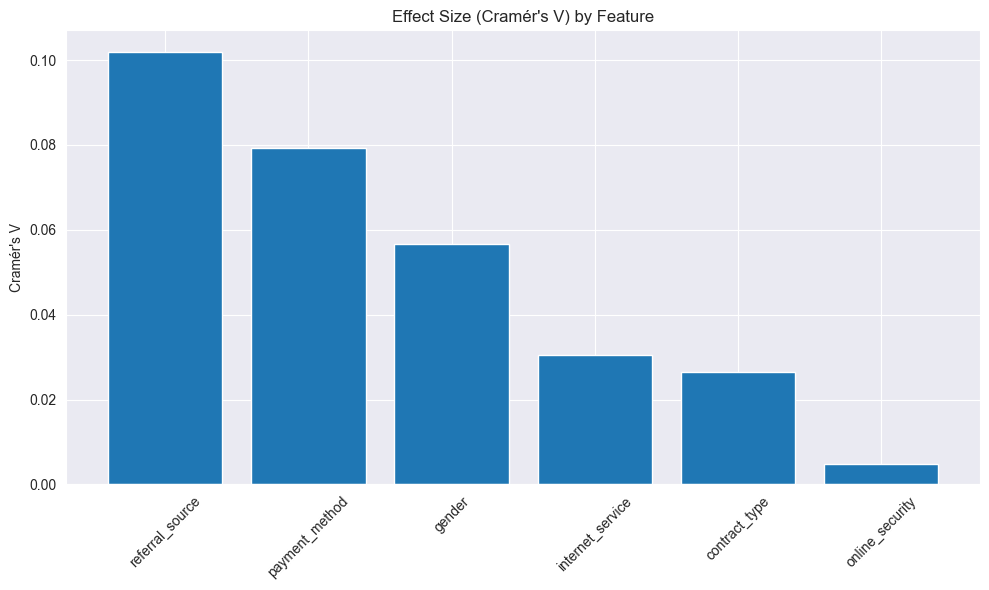

,Feature,Chi-Square,P-Value,Cramér's V,Effect Size,Is Significant,Strongest Category,Association Direction
5,referral_source,10.384533,0.320261,0.101905,Small,False,Friend,Positive
2,payment_method,6.275061,0.179527,0.079215,Negligible,False,Unknown,Positive
0,gender,3.221662,0.199722,0.056760,Negligible,False,Other,Negative
3,internet_service,0.929969,0.628145,0.030495,Negligible,False,DSL,Positive
1,contract_type,0.697207,0.705673,0.026498,Negligible,False,One year,Positive
4,online_security,0.023108,0.879175,0.004807,Negligible,False,No,Positive


In [9]:
cat_results = analyze_categorical_relationships(
    df,
    features=eda_cats,
    target=target_label,
    alpha=0.05,
)
display(cat_results)

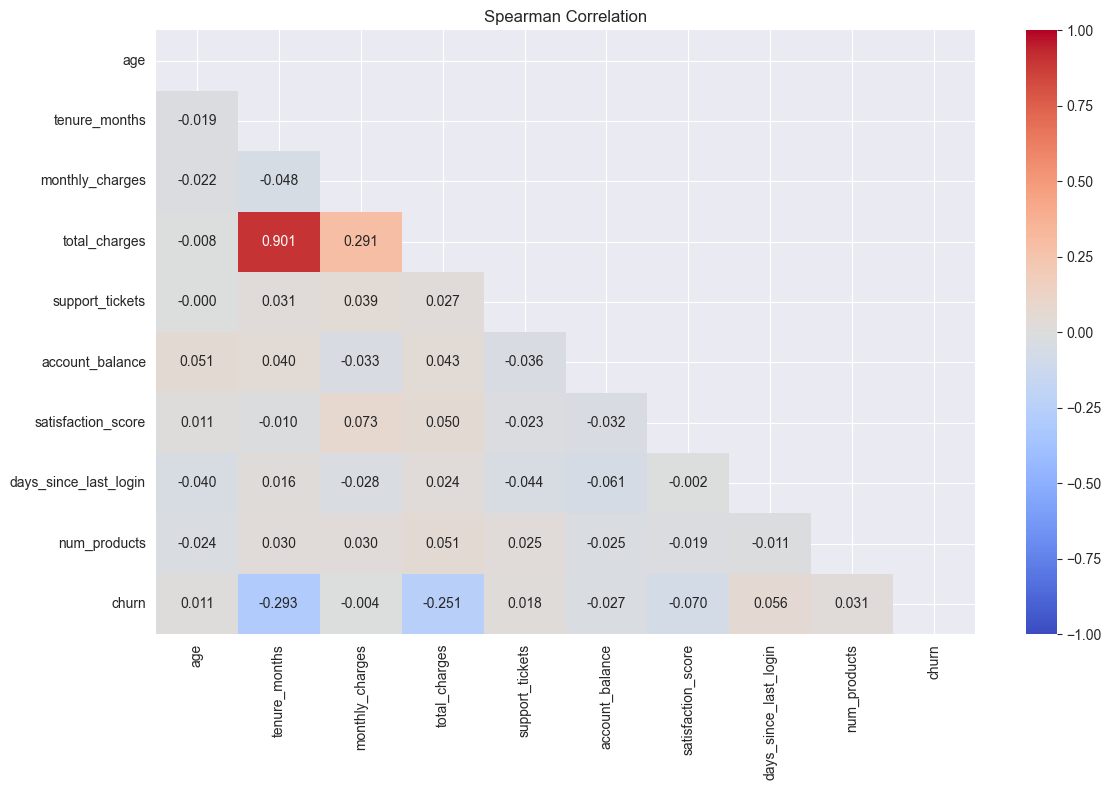

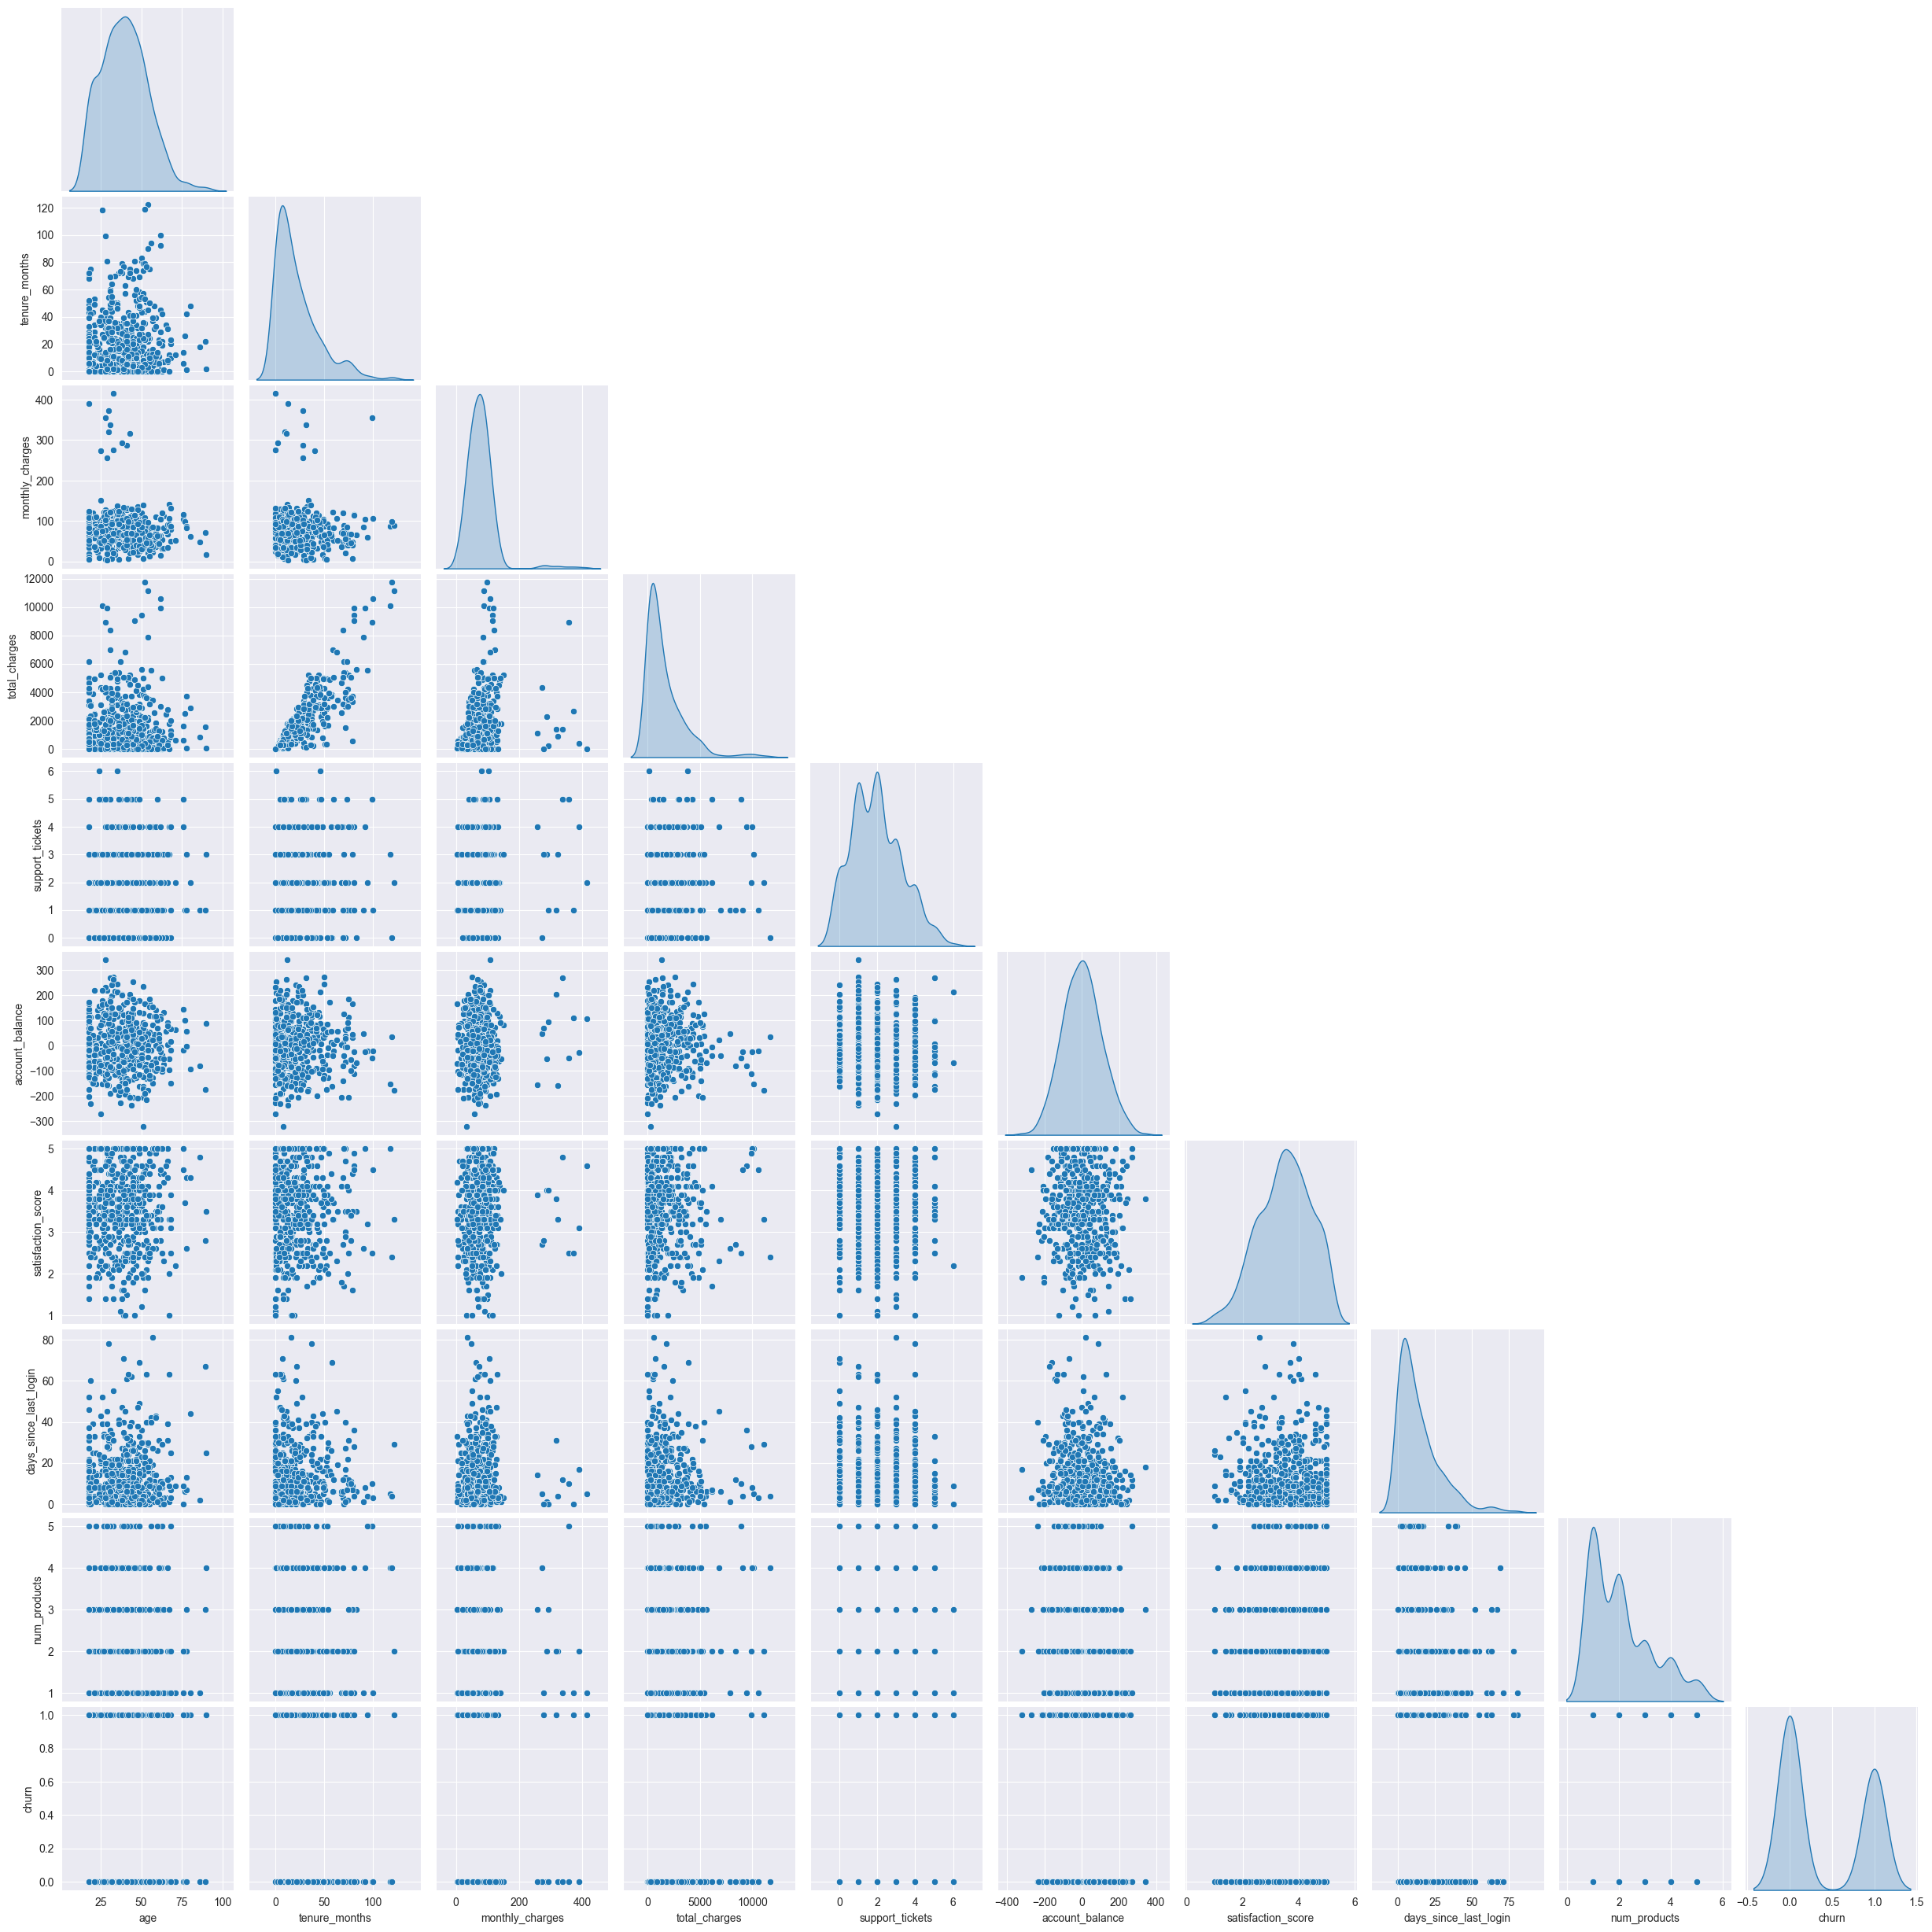

In [10]:
plot_correlation_heatmap(
    df,
    eda_nums + [target],
    corr_method="spearman",
    figsize=(12, 8),
)

# A sample keeps the pairplot readable and fast.
pairplot_data = df[eda_nums + [target]].dropna().sample(
    n=min(500, len(df)), random_state=42
)
sns.pairplot(pairplot_data, diag_kind="kde", corner=True)
plt.show()

### EDA takeaways
- Churn is imbalanced but not extreme, so accuracy alone is misleading.
- Short tenure and low satisfaction are visually associated with churn.
- Contract type and internet service show different churn profiles.
- `total_charges` is strongly related to tenure; tree models can handle the overlap, while linear models benefit from scaling and selection.

## **STAGE 5: TRAIN / VALIDATION / TEST SPLIT**

The split is stratified by `churn` and happens before imputation, outlier handling, encoding, selection, and scaling. The test set is 5% of the original data and is untouched until the final evaluation.

In [11]:
cols_to_drop = ["customer_id", "churn_label"]
X_raw = df.drop(columns=[target] + cols_to_drop)
y_raw = df[target]

X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X_raw, y_raw,
    test_size=0.25,
    random_state=42,
    stratify=y_raw,
)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw,
    test_size=0.2,
    random_state=42,
    stratify=y_temp_raw,
)

total = len(X_raw)
print(f"Total rows:   {total:,}")
print(f"Train:        {len(X_train_raw):,} ({len(X_train_raw)/total*100:.1f}%)")
print(f"Validation:   {len(X_val_raw):,} ({len(X_val_raw)/total*100:.1f}%)")
print(f"Test:         {len(X_test_raw):,} ({len(X_test_raw)/total*100:.1f}%)")
print()
print("Churn rate by split:")
print(f"  Train:      {y_train_raw.mean():.3f}")
print(f"  Validation: {y_val_raw.mean():.3f}")
print(f"  Test:       {y_test_raw.mean():.3f}")

Total rows:   1,000
Train:        750 (75.0%)
Validation:   200 (20.0%)
Test:         50 (5.0%)

Churn rate by split:
  Train:      0.395
  Validation: 0.395
  Test:       0.400


## **STAGE 6: PREPROCESSING FITTED ON TRAINING DATA**

### Missing-value imputation
Numeric columns use the training median; categorical columns use the training mode. Validation and test data receive the training statistics.

In [12]:
numeric_missing = [
    col for col in X_train_raw.columns
    if X_train_raw[col].isna().any() and pd.api.types.is_numeric_dtype(X_train_raw[col])
]
categorical_missing = [
    col for col in X_train_raw.columns
    if X_train_raw[col].isna().any() and col not in numeric_missing
]

train_medians = X_train_raw[numeric_missing].median()
train_modes = {}
for col in categorical_missing:
    mode = X_train_raw[col].mode()
    train_modes[col] = mode.iloc[0] if not mode.empty else "Unknown"

X_train_imp, _ = handle_missing_values(
    X_train_raw.copy(),
    columns=numeric_missing,
    strategy="median",
)
for col in categorical_missing:
    X_train_imp[col] = X_train_imp[col].fillna(train_modes[col])

def apply_training_imputation(X):
    X = X.copy()
    if numeric_missing:
        X[numeric_missing] = X[numeric_missing].fillna(train_medians)
    for col in categorical_missing:
        X[col] = X[col].fillna(train_modes[col])
    return X

X_val_imp = apply_training_imputation(X_val_raw)
X_test_imp = apply_training_imputation(X_test_raw)

print(f"Numeric columns imputed: {len(numeric_missing)}")
print(f"Categorical columns imputed: {len(categorical_missing)}")
print(f"Remaining train missing values: {X_train_imp.isna().sum().sum()}")

Numeric columns imputed: 6
Categorical columns imputed: 1
Remaining train missing values: 0


### Outlier handling
IQR limits are learned from training features only. Training rows outside the limits are removed; the same limits are applied to validation. The test set is not filtered.

In [13]:
outlier_cols = [col for col in eda_nums if col in X_train_imp.columns]

outlier_summary = filter_outliers(
    pd.concat([X_train_imp, y_train_raw], axis=1),
    columns=outlier_cols,
    method="iqr",
    threshold=1.5,
    detect_only=True,
    verbose=False,
)
display(outlier_summary)

train_mask = filter_outliers(
    X_train_imp,
    columns=outlier_cols,
    method="iqr",
    threshold=1.5,
    return_mask=True,
)[1]
X_train_clean = X_train_imp[train_mask].copy()
y_train_clean = y_train_raw[train_mask].copy()

def apply_training_limits(X, limits_df, columns):
    """Apply training-derived IQR limits to a validation/test feature frame."""
    mask = np.ones(len(X), dtype=bool)
    for _, row in limits_df.iterrows():
        col = row["Column Name"]
        if col in columns and col in X.columns:
            mask &= X[col].between(row["Lower Limit"], row["Upper Limit"]).to_numpy()
    return X[mask].copy(), mask

X_val_clean, val_mask = apply_training_limits(X_val_imp, outlier_summary, outlier_cols)
y_val_clean = y_val_raw[val_mask].copy()

print(f"Train after outlier removal: {len(X_train_clean):,} rows")
print(f"Validation after limits:     {len(X_val_clean):,} rows")
print(f"Test kept untouched:         {len(X_test_imp):,} rows")

,Column Name,Outlier Exist,Lower Limit,Upper Limit,Outlier Data,Non-Outlier Data,Outlier Percentage (%)
0,age,True,5.500000,73.500000,9,741,1.20
1,tenure_months,True,-28.500000,63.500000,46,704,6.13
2,monthly_charges,True,0.139360,143.672026,18,732,2.40
3,total_charges,True,-1685.437596,3864.949876,58,692,7.73
4,support_tickets,True,-2.000000,6.000000,1,749,0.13
5,account_balance,True,-278.049815,275.584716,6,744,0.80
6,satisfaction_score,False,1.000000,5.800000,0,750,0.00
7,days_since_last_login,True,-18.500000,41.500000,41,709,5.47
8,num_products,False,-2.000000,6.000000,0,750,0.00


Train after outlier removal: 607 rows
Validation after limits:     156 rows
Test kept untouched:         50 rows


### Feature encoding
- `contract_type` is ordinal: Monthly < One year < Two year.
- `gender`, `internet_service`, `payment_method`, and `referral_source` are one-hot encoded.
- `online_security` is binary-encoded.
- Encoders are fitted on training data and reused for validation and test.

**API note:** the current `feature_encoding` supports `binary_columns` directly, so the old manual `map({...})` step is no longer needed.

In [14]:
ordinal_cols = ["contract_type"]
ordinal_categories = {
    "contract_type": ["Monthly", "One year", "Two year"],
}
nominal_cols = ["gender", "internet_service", "payment_method", "referral_source"]
binary_cols = ["online_security"]

X_train_encoded, encoders = feature_encoding(
    data=X_train_clean.copy(),
    ordinal_columns=ordinal_cols,
    nominal_columns=nominal_cols,
    binary_columns=binary_cols,
    ordinal_categories=ordinal_categories,
    handle_unknown="ignore",
)
X_val_encoded, _ = feature_encoding(
    data=X_val_clean.copy(),
    ordinal_columns=ordinal_cols,
    nominal_columns=nominal_cols,
    binary_columns=binary_cols,
    ordinal_categories=ordinal_categories,
    encoders=encoders,
    handle_unknown="ignore",
)
X_test_encoded, _ = feature_encoding(
    data=X_test_imp.copy(),
    ordinal_columns=ordinal_cols,
    nominal_columns=nominal_cols,
    binary_columns=binary_cols,
    ordinal_categories=ordinal_categories,
    encoders=encoders,
    handle_unknown="ignore",
)

print(f"Encoded training shape: {X_train_encoded.shape}")
print(X_train_encoded.columns.tolist())

Encoded training shape: (607, 28)
['contract_type', 'gender_Male', 'gender_Other', 'internet_service_Fiber Optic', 'internet_service_No', 'payment_method_Credit Card', 'payment_method_Electronic Check', 'payment_method_Mailed Check', 'payment_method_Unknown', 'referral_source_Email', 'referral_source_Facebook', 'referral_source_Friend', 'referral_source_Google', 'referral_source_Instagram', 'referral_source_Other', 'referral_source_TV Ad', 'referral_source_Twitter', 'referral_source_Unknown', 'age', 'tenure_months', 'monthly_charges', 'total_charges', 'support_tickets', 'account_balance', 'online_security', 'satisfaction_score', 'days_since_last_login', 'num_products']


## **STAGE 7: FEATURE SELECTION**

Correlation and univariate importance are computed on training data only. Highly correlated candidates are pruned before modeling.

In [15]:
df_train_encoded = pd.concat(
    [X_train_encoded.reset_index(drop=True), y_train_clean.reset_index(drop=True)],
    axis=1,
)
feature_feature_df, feature_target_df = calculate_correlation_tabular(
    df_train_encoded,
    target_col=target,
    method="spearman",
    corr_type="both",
)

Correlation Between Features:


,A,B,Corr Value,Corr Type
0,tenure_months,total_charges,0.735305,Positive
1,internet_service_Fiber Optic,internet_service_No,0.471744,Negative
2,payment_method_Credit Card,payment_method_Electronic Check,0.355213,Negative
3,payment_method_Credit Card,payment_method_Mailed Check,0.276755,Negative
4,payment_method_Credit Card,payment_method_Unknown,0.220153,Negative
5,monthly_charges,total_charges,0.216332,Positive
6,payment_method_Electronic Check,payment_method_Mailed Check,0.206144,Negative
7,referral_source_Friend,referral_source_Google,0.198464,Negative
8,referral_source_Facebook,referral_source_Google,0.189313,Negative
9,referral_source_Google,referral_source_TV Ad,0.168953,Negative



Correlation of Features to Target:


,Feature,Corr Value,Corr Type
0,tenure_months,0.329014,Negative
1,total_charges,0.237706,Negative
2,referral_source_Friend,0.114742,Positive
3,monthly_charges,0.107506,Positive
4,referral_source_Unknown,0.080655,Negative
5,num_products,0.063007,Positive
6,payment_method_Unknown,0.054342,Positive
7,gender_Other,0.052518,Negative
8,internet_service_No,0.051383,Negative
9,referral_source_Google,0.049029,Negative


In [16]:
importance_anova = calculate_feature_importance(
    X=X_train_encoded,
    y=y_train_clean.reset_index(drop=True),
    task="classification",
    method="anova",
    k="all",
)
importance_mi = calculate_feature_importance(
    X=X_train_encoded,
    y=y_train_clean.reset_index(drop=True),
    task="classification",
    method="mutual_info",
    k="all",
)

print("Top ANOVA F features")
display(importance_anova.head(15).reset_index(drop=True))
print("Top mutual-information features")
display(importance_mi.head(15).reset_index(drop=True))

Top ANOVA F features


,Feature,Score,P_Values
0,tenure_months,57.310630,1.395964e-13
1,total_charges,26.928004,2.886406e-07
2,referral_source_Friend,8.071482,4.648129e-03
3,monthly_charges,5.586452,1.841506e-02
4,referral_source_Unknown,3.961438,4.700344e-02
5,num_products,2.072412,1.505013e-01
6,support_tickets,1.918029,1.665846e-01
7,payment_method_Unknown,1.791887,1.811992e-01
8,gender_Other,1.673273,1.963143e-01
9,internet_service_No,1.601583,2.061661e-01


Top mutual-information features


,Feature,Score,P_Values
0,tenure_months,0.074868,None
1,satisfaction_score,0.038199,None
2,referral_source_Friend,0.036949,None
3,gender_Other,0.023880,None
4,referral_source_Unknown,0.021497,None
5,monthly_charges,0.019455,None
6,support_tickets,0.019320,None
7,referral_source_Google,0.016758,None
8,total_charges,0.016716,None
9,referral_source_Email,0.016634,None


In [17]:
candidate_features = importance_mi.head(20)["Feature"].tolist()
corr_matrix = X_train_encoded[candidate_features].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if (upper[col] > 0.9).any()]

selected_cols = [col for col in candidate_features if col not in to_drop]
if len(selected_cols) < 8:
    selected_cols = importance_mi.head(12)["Feature"].tolist()

X_train_selected = X_train_encoded[selected_cols].copy()
X_val_selected = X_val_encoded[selected_cols].copy()
X_test_selected = X_test_encoded[selected_cols].copy()

print(f"Selected {len(selected_cols)} features")
print(selected_cols)
print(f"Train shape: {X_train_selected.shape}")
print(f"Validation shape: {X_val_selected.shape}")
print(f"Test shape: {X_test_selected.shape}")

Selected 20 features
['tenure_months', 'satisfaction_score', 'referral_source_Friend', 'gender_Other', 'referral_source_Unknown', 'monthly_charges', 'support_tickets', 'referral_source_Google', 'total_charges', 'referral_source_Email', 'contract_type', 'payment_method_Credit Card', 'gender_Male', 'days_since_last_login', 'referral_source_Facebook', 'payment_method_Unknown', 'internet_service_No', 'internet_service_Fiber Optic', 'payment_method_Electronic Check', 'payment_method_Mailed Check']
Train shape: (607, 20)
Validation shape: (156, 20)
Test shape: (50, 20)


### Feature scaling
Binary-like columns use min-max scaling; continuous columns use standardization. The scalers are fitted on training data and reused for validation and test.

In [18]:
binary_like = [col for col in selected_cols if X_train_encoded[col].nunique() <= 2]
continuous_cols = [col for col in selected_cols if col not in binary_like]

scaling_config = {}
if continuous_cols:
    scaling_config["standard"] = {"columns": continuous_cols}
if binary_like:
    scaling_config["minmax"] = {"columns": binary_like}

X_train_scaled, scalers = feature_scaling(
    X_train_selected,
    scaling_config=scaling_config,
)
X_val_scaled, _ = feature_scaling(
    X_val_selected,
    scaling_config=scaling_config,
    scaler=scalers,
)
X_test_scaled, _ = feature_scaling(
    X_test_selected,
    scaling_config=scaling_config,
    scaler=scalers,
)

print(f"Continuous columns scaled with standard: {len(continuous_cols)}")
print(f"Binary-like columns scaled with minmax: {len(binary_like)}")
print(f"Train scaled shape: {X_train_scaled.shape}")

Continuous columns scaled with standard: 7
Binary-like columns scaled with minmax: 13
Train scaled shape: (607, 20)


## **STAGE 8: BASELINE CLASSIFICATION MODELS**

Six baseline pipelines are trained on the scaled training data and evaluated on the validation set. Cross-validated metrics are computed on the training set with repeated stratified K-fold.

In [19]:
model_keys = [
    "logisticregression", "knn", "decisiontree",
    "randomforest", "gb", "xgboost",
]
display_names = {
    "logisticregression": "Logistic Regression",
    "knn": "K-Nearest Neighbors",
    "decisiontree": "Decision Tree",
    "randomforest": "Random Forest",
    "gb": "Gradient Boosting",
    "xgboost": "XGBoost",
}

baseline_models = {
    display_names[key]: get_model_pipeline_classification(key, random_state=42)
    for key in model_keys
}

for name, model in baseline_models.items():
    model.fit(X_train_scaled, y_train_clean)
    print(f"Trained {name}")

Trained Logistic Regression
Trained K-Nearest Neighbors
Trained Decision Tree
Trained Random Forest
Trained Gradient Boosting
Trained XGBoost


In [20]:
baseline_metrics = {}
for name, model in baseline_models.items():
    baseline_metrics[name] = eval_classification(
        model=model,
        X_train=X_train_scaled,
        y_train=y_train_clean,
        X_test=X_val_scaled,
        y_test=y_val_clean,
        plot_confusion_matrix=False,
        plot_roc_curve=False,
        plot_pr_curve=False,
        plot_calibration_curve=False,
        plot_threshold_analysis=False,
        n_splits=5,
        n_repeats=2,
        display=False,
        show_plots=False,
    )
    print(f"Evaluated {name}")

Evaluated Logistic Regression
Evaluated K-Nearest Neighbors
Evaluated Decision Tree
Evaluated Random Forest
Evaluated Gradient Boosting
Evaluated XGBoost


In [21]:
comparison = compare_cv_metrics_classification(baseline_metrics, as_numeric=True)
comparison = comparison.sort_values("F1", ascending=False).reset_index(drop=True)
display(comparison)

,Model,ACCURACY,PRECISION,RECALL,F1,ROC_AUC
0,Logistic Regression,0.662343,0.600972,0.477253,0.528368,0.672199
1,Random Forest,0.641736,0.565754,0.460629,0.505646,0.660467
2,Gradient Boosting,0.627713,0.540810,0.456463,0.492914,0.640075
3,XGBoost,0.598930,0.499514,0.454677,0.474326,0.605843
4,Decision Tree,0.565161,0.459452,0.477381,0.467513,0.550334
5,K-Nearest Neighbors,0.581601,0.466741,0.355442,0.402903,0.564679


In [22]:
best_model_name = comparison.iloc[0]["Model"]
best_model_key = {name: key for key, name in display_names.items()}[best_model_name]
print(f"Best baseline by cross-validated F1: {best_model_name}")
print(f"Model key: {best_model_key}")

Best baseline by cross-validated F1: Logistic Regression
Model key: logisticregression


## **STAGE 9: HYPERPARAMETER TUNING**

The best baseline is tuned with randomized search on the training set. The validation set is used only to report the holdout score.

In [23]:
tuned_search, fit_time = tune_single_model_classification(
    model_name=best_model_key,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_val_scaled,
    y_test=y_val_clean,
    scoring="f1",
    search_method="random",
    n_iter=20,
    n_splits=3,
    n_repeats=1,
    random_state=42,
    display=False,
    plot_validation_curves=False,
    plot_learning_curves=False,
    progress_bar=False,
    show=False,
)

print(f"Tuning time: {fit_time:.2f} seconds")
print(f"Best CV F1: {tuned_search.best_score_:.4f}")
print(f"Best parameters: {tuned_search.best_params_}")

Tuning time: 7.22 seconds
Best CV F1: 0.5308
Best parameters: {'lr__solver': 'lbfgs', 'lr__penalty': 'l2', 'lr__max_iter': 1000, 'lr__C': 6.866488450042998}


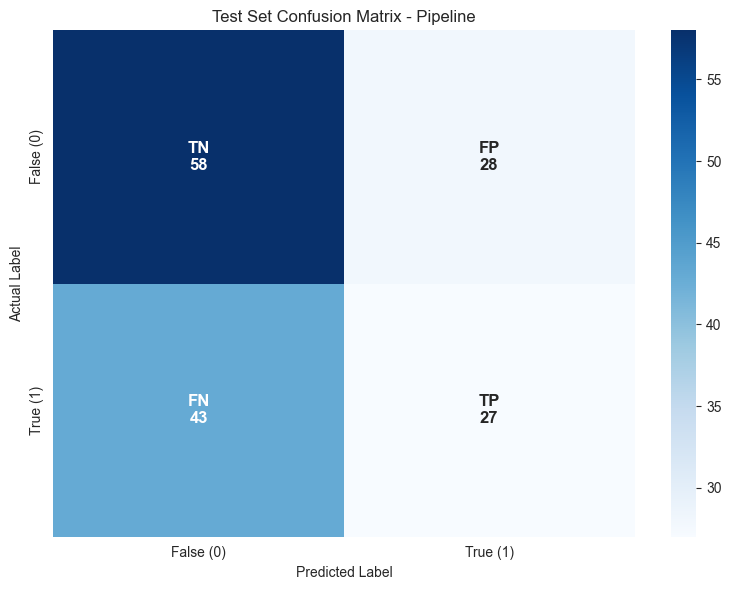

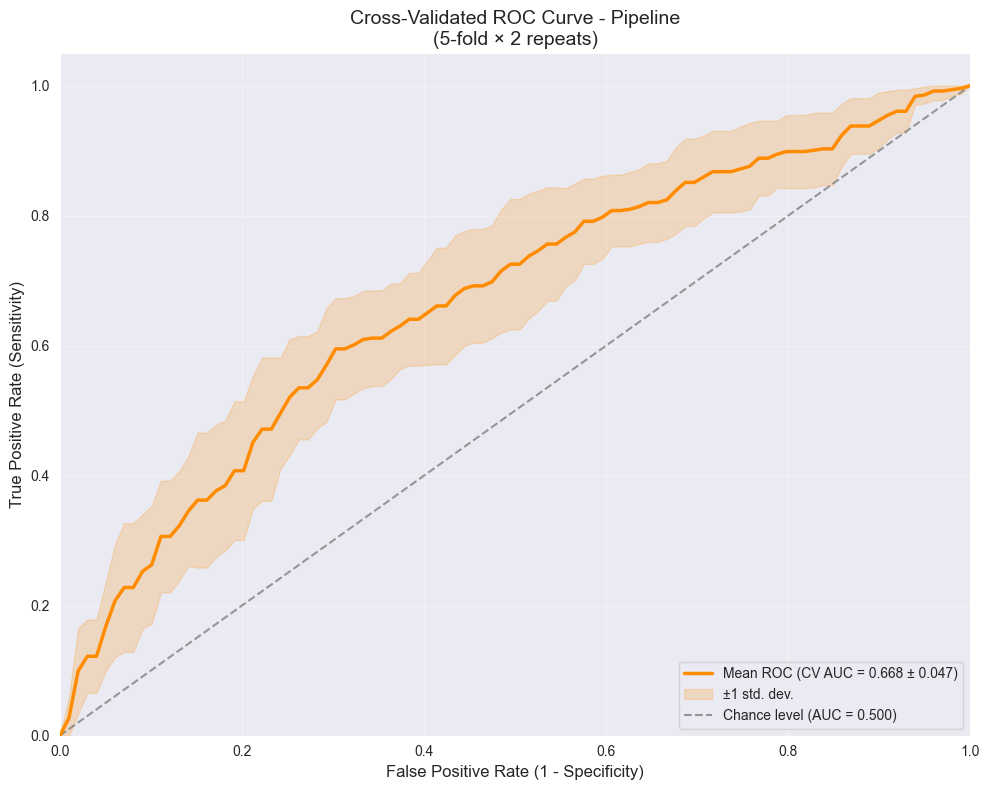

In [24]:
tuned_model = tuned_search.best_estimator_

tuned_metrics = eval_classification(
    model=tuned_model,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_val_scaled,
    y_test=y_val_clean,
    plot_confusion_matrix=True,
    plot_roc_curve=True,
    plot_pr_curve=False,
    plot_calibration_curve=False,
    plot_threshold_analysis=False,
    n_splits=5,
    n_repeats=2,
    display=False,
)

## **STAGE 10: BUSINESS IMPACT SIMULATION**

The simulation uses the validation-set confusion matrix and explicit assumptions. Change the dollar values to match the business.

In [25]:
cm = tuned_metrics["confusion_matrix"]
tn, fp, fn, tp = cm.ravel()

avg_customer_value = 1000.0   # annual revenue per retained customer
retention_cost = 100.0        # cost to target one customer
retention_success_rate = 0.70 # share of targeted churners who stay

customers_targeted = tp + fp
customers_retained = tp * retention_success_rate
total_retention_cost = customers_targeted * retention_cost
revenue_saved = customers_retained * avg_customer_value
net_benefit = revenue_saved - total_retention_cost
roi = net_benefit / total_retention_cost * 100 if total_retention_cost > 0 else np.nan

impact = pd.DataFrame({
    "Metric": [
        "True positives", "False positives", "False negatives", "True negatives",
        "Customers targeted", "Expected retained", "Retention cost",
        "Revenue saved", "Net benefit", "ROI (%)",
    ],
    "Value": [
        tp, fp, fn, tn,
        customers_targeted, f"{customers_retained:.0f}",
        f"${total_retention_cost:,.0f}",
        f"${revenue_saved:,.0f}",
        f"${net_benefit:,.0f}",
        f"{roi:.1f}%",
    ],
})
display(impact)

,Metric,Value
0,True positives,27
1,False positives,28
2,False negatives,43
3,True negatives,58
4,Customers targeted,55
5,Expected retained,19
6,Retention cost,"$5,500"
7,Revenue saved,"$18,900"
8,Net benefit,"$13,400"
9,ROI (%),243.6%


## **STAGE 11: FINAL TEST-SET EVALUATION**

The test set has not been used for imputation, outlier limits, encoding, feature selection, scaling, or tuning. This is the final unbiased estimate.

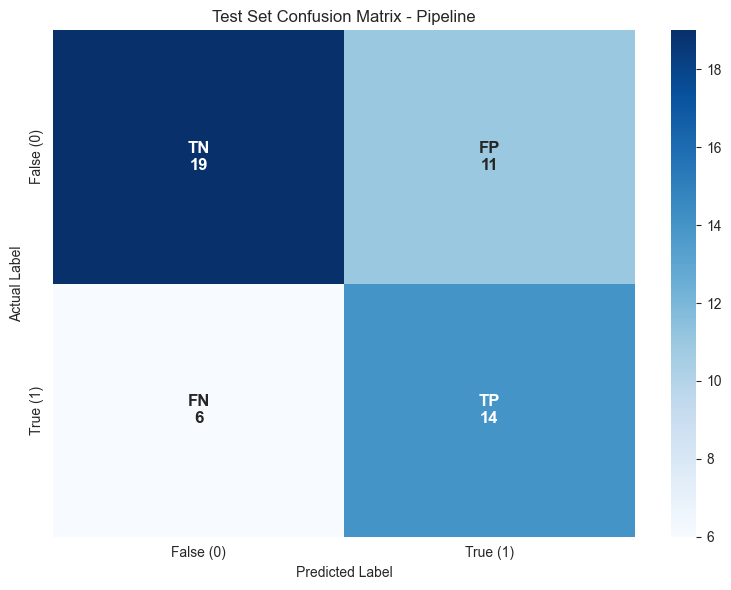

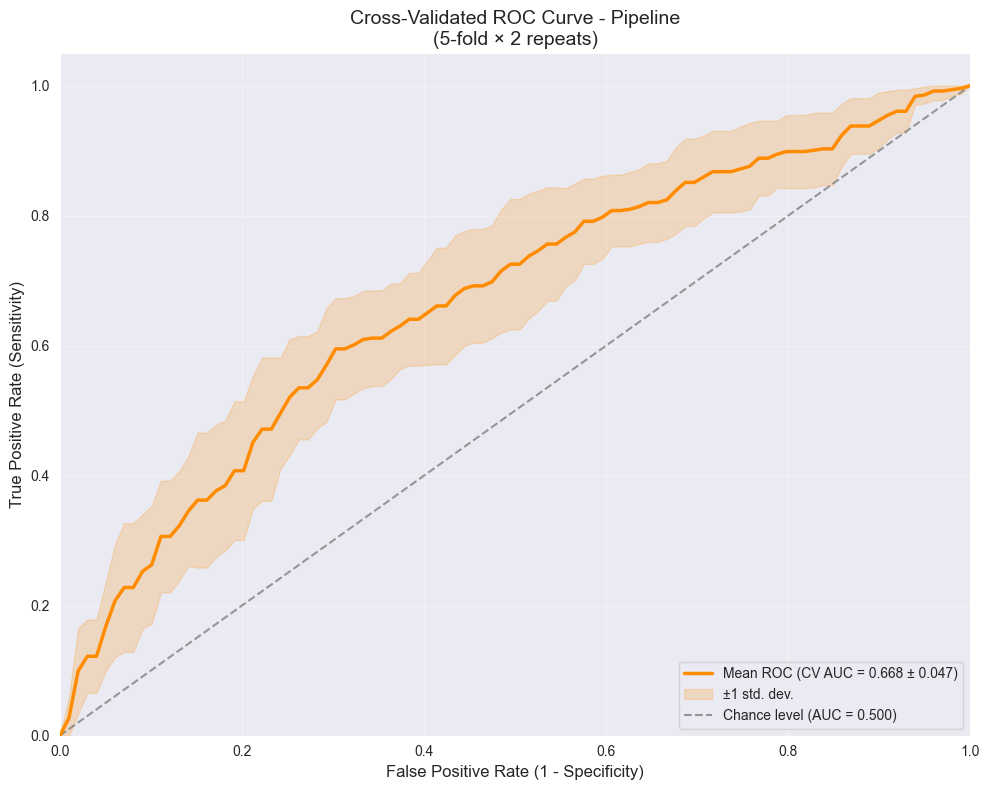

,Metric,Test
0,Accuracy,0.660000
1,Precision,0.560000
2,Recall,0.700000
3,F1,0.622222
4,ROC-AUC,0.753333


In [26]:
metrics_test = eval_classification(
    model=tuned_model,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_test_scaled,
    y_test=y_test_raw,
    plot_confusion_matrix=True,
    plot_roc_curve=True,
    plot_pr_curve=False,
    plot_calibration_curve=False,
    plot_threshold_analysis=False,
    n_splits=5,
    n_repeats=2,
    display=False,
)

test_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Test": [
        metrics_test["accuracy"]["test"],
        metrics_test["precision"]["test"],
        metrics_test["recall"]["test"],
        metrics_test["f1"]["test"],
        metrics_test["roc_auc"]["test"],
    ],
})
display(test_summary)

## **STAGE 12: CONCLUSION AND NEXT STEPS**

### What the workflow shows
- The model is trained with a leakage-safe pipeline: split first, then impute, filter outliers, encode, select, and scale using training statistics only.
- Cross-validated comparison gives a more stable model ranking than a single validation split.
- The tuned model is evaluated on validation for model selection and on the test set for the final estimate.
- Recall is the primary business metric; precision and F1 keep the retention team from chasing too many false alarms.

### Practical recommendations
1. Choose an operating threshold that meets the recall target while keeping precision acceptable. `eval_classification` can produce a threshold-analysis plot when `plot_threshold_analysis=True`.
2. Validate the model on a future time window, not only a random split.
3. Monitor churn-score drift and retrain when the customer mix or pricing changes.
4. Combine the model with business rules (for example, do not target customers already in a retention contract).
5. Revisit the dollar assumptions in the business-impact simulation with finance.

### Limitations
- The dataset is synthetic and contains deliberate data-quality issues.
- The test set is small (5% of the data), so the final metrics have meaningful uncertainty.
- Outlier removal changes the population the model is trained on; extreme customers may need a separate review process.
- A churn prediction is not causal: targeting a customer does not guarantee retention.